# Research Question 2

Which product categories generate the highest real profit margin and to what extent is this profitability reduced by specific return rates in the individual clusters?

In [1]:
# Bibliotheken importieren
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import create_engine

# Verbindung zu eurem gemeinsamen Data Mart herstellen
engine = create_engine("trino://admin@trino:8080/iceberg")

# Die vorbereiteten Data-Mart-Tabellen laden
fact_sales = pd.read_sql(
    "SELECT * FROM iceberg.datamart.fact_sales",
    con=engine
)

dim_products = pd.read_sql(
    "SELECT * FROM iceberg.datamart.dim_products",
    con=engine
)

# Falls der Data Mart mehrfach ausgeführt wurde,
# entfernen wir doppelte Einträge anhand der eindeutigen IDs.
fact_sales = fact_sales.drop_duplicates(subset=["order_item_id"])
dim_products = dim_products.drop_duplicates(subset=["product_id"])

print("fact_sales:", fact_sales.shape)
print("dim_products:", dim_products.shape)

fact_sales: (181759, 11)
dim_products: (29120, 10)


In [2]:
# Schritt 2: Data Mart für Research Question 2 vorbereiten
#
# fact_sales enthält die Verkaufsdaten, zum Beispiel:
# - product_id
# - status
# - sale_price
# - inventory_cost
# - is_returned
#
# dim_products enthält Produktinformationen, zum Beispiel:
# - category
# - brand
# - department
# - retail_price
#
# Wir verbinden beide Tabellen über product_id.
# Danach können wir Profitabilität pro Produktkategorie analysieren.

# Nur die wichtigen Produktspalten auswählen.
# Das macht die Tabelle übersichtlicher.
product_columns = [
    "product_id",
    "product_name",
    "category",
    "brand",
    "department",
    "retail_price"
]

# Fact Table und Produktdimension verbinden.
sales_mart = fact_sales.merge(
    dim_products[product_columns],
    on="product_id",
    how="left"
)

# Für die finale Profitabilität verwenden wir nur:
# - Complete = Bestellung abgeschlossen
# - Returned = Artikel wurde zurückgegeben
sales_mart = sales_mart[
    sales_mart["status"].isin(["Complete", "Returned"])
].copy()

# Zahlenfelder sicher als Zahlen formatieren.
sales_mart["sale_price"] = pd.to_numeric(
    sales_mart["sale_price"],
    errors="coerce"
)

sales_mart["inventory_cost"] = pd.to_numeric(
    sales_mart["inventory_cost"],
    errors="coerce"
)

# Zeilen mit fehlenden Preisen oder Kosten entfernen.
sales_mart = sales_mart.dropna(
    subset=["sale_price", "inventory_cost"]
)

# Artikel mit einem Verkaufspreis von 0 entfernen.
sales_mart = sales_mart[
    sales_mart["sale_price"] > 0
]

print("Sales Mart für Research Question 2:", sales_mart.shape)
print("\nStatusverteilung:")
print(sales_mart["status"].value_counts())

Sales Mart für Research Question 2: (63841, 16)

Statusverteilung:
status
Complete    45609
Returned    18232
Name: count, dtype: int64


In [3]:
# Schritt 3: Profitabilität und Retouren berechnen
#
# Ziel:
# Wir berechnen Umsatz, Bruttogewinn und die echte Profitabilität
# nach Berücksichtigung von Retouren.
#
# Annahme bei Retouren:
# - Der Umsatz geht verloren.
# - Die Produktkosten bleiben als Verlust bestehen.

# Umsatz entspricht dem Verkaufspreis.
sales_mart["revenue"] = sales_mart["sale_price"]

# Bruttogewinn vor Retouren:
# Verkaufspreis minus Inventarkosten.
sales_mart["gross_profit"] = (
    sales_mart["sale_price"] -
    sales_mart["inventory_cost"]
)

# Bruttomarge vor Retouren.
sales_mart["gross_profit_margin"] = (
    sales_mart["gross_profit"] /
    sales_mart["sale_price"]
)

# Das Retouren-Flag wurde bereits im gemeinsamen Data Mart erstellt.
# Wir wandeln es zur Sicherheit in True oder False um.
sales_mart["return_flag"] = (
    sales_mart["is_returned"]
    .astype(int)
    .eq(1)
)

# Return-adjusted Profit:
# Bei einer Retoure werden die Inventarkosten als Verlust gezählt.
# Bei einer abgeschlossenen Bestellung bleibt der normale Gewinn bestehen.
sales_mart["return_adjusted_profit"] = np.where(
    sales_mart["return_flag"],
    -sales_mart["inventory_cost"],
    sales_mart["gross_profit"]
)

# Return-adjusted Profit Margin:
# Diese Kennzahl zeigt die echte Profitabilität nach Retouren.
sales_mart["return_adjusted_profit_margin"] = (
    sales_mart["return_adjusted_profit"] /
    sales_mart["sale_price"]
)

print("Profitabilitätskennzahlen wurden berechnet.")

# Kurze Kontrolle der neuen Spalten
display(
    sales_mart[
        [
            "category",
            "status",
            "sale_price",
            "inventory_cost",
            "gross_profit",
            "return_flag",
            "return_adjusted_profit",
            "return_adjusted_profit_margin"
        ]
    ].head()
)

Profitabilitätskennzahlen wurden berechnet.


,category,status,sale_price,inventory_cost,gross_profit,return_flag,return_adjusted_profit,return_adjusted_profit_margin
0,Plus,Returned,139.99,75.31,64.68,True,-75.31,-0.537967
1,Pants,Returned,36.99,18.38,18.61,True,-18.38,-0.496891
2,Pants,Returned,36.99,16.98,20.01,True,-16.98,-0.459043
4,Leggings,Complete,12.99,7.79,5.20,False,5.20,0.400308
5,Jumpsuits & Rompers,Complete,12.99,6.46,6.53,False,6.53,0.502694


In [4]:
# Schritt 4: Profitabilität pro Produktkategorie berechnen
#
# Ziel:
# Wir fassen alle Verkäufe nach Produktkategorie zusammen.
# Dadurch sehen wir:
# - welche Kategorien die höchste echte Profit Margin haben
# - welche Kategorien viele Retouren haben
# - wie stark Retouren die Marge reduzieren

category_profit = sales_mart.groupby("category").agg(
    # Anzahl aller Artikel in der Kategorie
    number_of_items=("order_item_id", "count"),

    # Gesamtumsatz der Kategorie
    total_revenue=("revenue", "sum"),

    # Gesamtkosten der Kategorie
    total_cost=("inventory_cost", "sum"),

    # Bruttogewinn vor Retouren
    gross_profit=("gross_profit", "sum"),

    # Gewinn nach Berücksichtigung von Retouren
    return_adjusted_profit=("return_adjusted_profit", "sum"),

    # Anzahl der retournierten Artikel
    returned_items=("return_flag", "sum")
).reset_index()

# Bruttomarge vor Retouren
category_profit["gross_profit_margin"] = (
    category_profit["gross_profit"] /
    category_profit["total_revenue"]
)

# Echte Profit Margin nach Retouren
category_profit["return_adjusted_profit_margin"] = (
    category_profit["return_adjusted_profit"] /
    category_profit["total_revenue"]
)

# Retourenquote
category_profit["return_rate"] = (
    category_profit["returned_items"] /
    category_profit["number_of_items"]
)

# Margenverlust durch Retouren
category_profit["margin_reduction_due_to_returns"] = (
    category_profit["gross_profit_margin"] -
    category_profit["return_adjusted_profit_margin"]
)

# Kategorien nach echter Profitabilität sortieren
category_profit = category_profit.sort_values(
    "return_adjusted_profit_margin",
    ascending=False
)

# Top 10 Kategorien anzeigen
display(category_profit.head(10))

,category,number_of_items,total_revenue,total_cost,gross_profit,return_adjusted_profit,returned_items,gross_profit_margin,return_adjusted_profit_margin,return_rate,margin_reduction_due_to_returns
2,Blazers & Jackets,1084,97633.77,36882.34,60751.43,33502.83,294,0.622238,0.343148,0.271218,0.279090
0,Accessories,3390,148128.70,59352.71,88775.99,48222.81,945,0.599317,0.325547,0.278761,0.273770
19,Socks & Hosiery,1311,21824.08,8743.76,13080.32,6690.54,352,0.599353,0.306567,0.268497,0.292786
16,Skirts,763,42405.61,16985.82,25419.79,12998.04,203,0.599444,0.306517,0.266055,0.292927
1,Active,3270,171256.21,71751.66,99504.55,50936.86,947,0.581027,0.297431,0.289602,0.283597
21,Suits & Sport Coats,1792,236409.62,94920.26,141489.36,68524.82,555,0.598492,0.289856,0.309710,0.308636
11,Outerwear & Coats,3218,462487.21,205734.09,256753.12,123830.02,919,0.555157,0.267748,0.285581,0.287409
10,Maternity,1768,91840.25,40564.30,51275.95,23244.15,530,0.558317,0.253093,0.299774,0.305223
25,Underwear,2680,73354.93,34492.65,38862.28,18428.87,765,0.529784,0.251229,0.285448,0.278555
4,Dresses,1896,157382.64,71053.21,86329.43,39441.78,548,0.548532,0.250611,0.289030,0.297921


In [5]:
# Schritt 5: Preiscluster und Clusteranalyse erstellen
#
# Ziel:
# Die Forschungsfrage erwähnt "individual clusters".
# Deshalb teilen wir die Produkte nach ihrem Verkaufspreis in drei Gruppen:
# - Low Price
# - Medium Price
# - High Price
#
# pd.qcut teilt die Daten so auf, dass ungefähr gleich viele Artikel
# in jedem Preiscluster liegen.

# Preiscluster auf Basis des sale_price erstellen
sales_mart["price_cluster"] = pd.qcut(
    sales_mart["sale_price"],
    q=3,
    labels=["Low Price", "Medium Price", "High Price"],
    duplicates="drop"
)

# Profitabilität nach Kategorie und Preiscluster berechnen
cluster_profit = sales_mart.groupby(
    ["category", "price_cluster"],
    observed=True
).agg(
    # Anzahl der Artikel in dieser Kategorie und Preisgruppe
    number_of_items=("order_item_id", "count"),

    # Gesamtumsatz
    total_revenue=("revenue", "sum"),

    # Gewinn vor Retouren
    gross_profit=("gross_profit", "sum"),

    # Gewinn nach Berücksichtigung von Retouren
    return_adjusted_profit=("return_adjusted_profit", "sum"),

    # Anzahl der Retouren
    returned_items=("return_flag", "sum")
).reset_index()

# Bruttomarge vor Retouren
cluster_profit["gross_profit_margin"] = (
    cluster_profit["gross_profit"] /
    cluster_profit["total_revenue"]
)

# Echte Profit Margin nach Retouren
cluster_profit["return_adjusted_profit_margin"] = (
    cluster_profit["return_adjusted_profit"] /
    cluster_profit["total_revenue"]
)

# Retourenquote
cluster_profit["return_rate"] = (
    cluster_profit["returned_items"] /
    cluster_profit["number_of_items"]
)

# Wie stark Retouren die Marge reduzieren
cluster_profit["margin_reduction_due_to_returns"] = (
    cluster_profit["gross_profit_margin"] -
    cluster_profit["return_adjusted_profit_margin"]
)

# Nach echter Profitabilität sortieren
cluster_profit = cluster_profit.sort_values(
    "return_adjusted_profit_margin",
    ascending=False
)

# Die zehn besten Kategorie-Cluster-Kombinationen anzeigen
display(cluster_profit.head(10))

,category,price_cluster,number_of_items,total_revenue,gross_profit,return_adjusted_profit,returned_items,gross_profit_margin,return_adjusted_profit_margin,return_rate,margin_reduction_due_to_returns
6,Blazers & Jackets,Low Price,383,6148.24,3819.79,2362.72,97,0.621282,0.384292,0.253264,0.236990
49,Skirts,Medium Price,256,10638.24,6386.15,3843.91,61,0.600301,0.361330,0.238281,0.238972
64,Suits & Sport Coats,Medium Price,256,10643.21,6363.40,3745.57,63,0.597884,0.351921,0.246094,0.245962
48,Skirts,Low Price,284,5322.24,3191.63,1858.11,71,0.599678,0.349122,0.250000,0.250556
8,Blazers & Jackets,High Price,527,83610.10,52080.38,28538.93,146,0.622896,0.341334,0.277040,0.281562
57,Socks & Hosiery,Low Price,1207,17579.13,10515.61,5991.75,310,0.598187,0.340845,0.256835,0.257343
1,Accessories,Medium Price,634,23811.59,14236.45,8017.87,165,0.597879,0.336721,0.260252,0.261158
77,Underwear,High Price,58,5598.05,2942.20,1876.93,12,0.525576,0.335283,0.206897,0.190293
7,Blazers & Jackets,Medium Price,174,7875.43,4851.26,2601.18,51,0.615999,0.330291,0.293103,0.285709
2,Accessories,High Price,798,94277.30,56551.57,30909.10,217,0.599843,0.327853,0.271930,0.271990


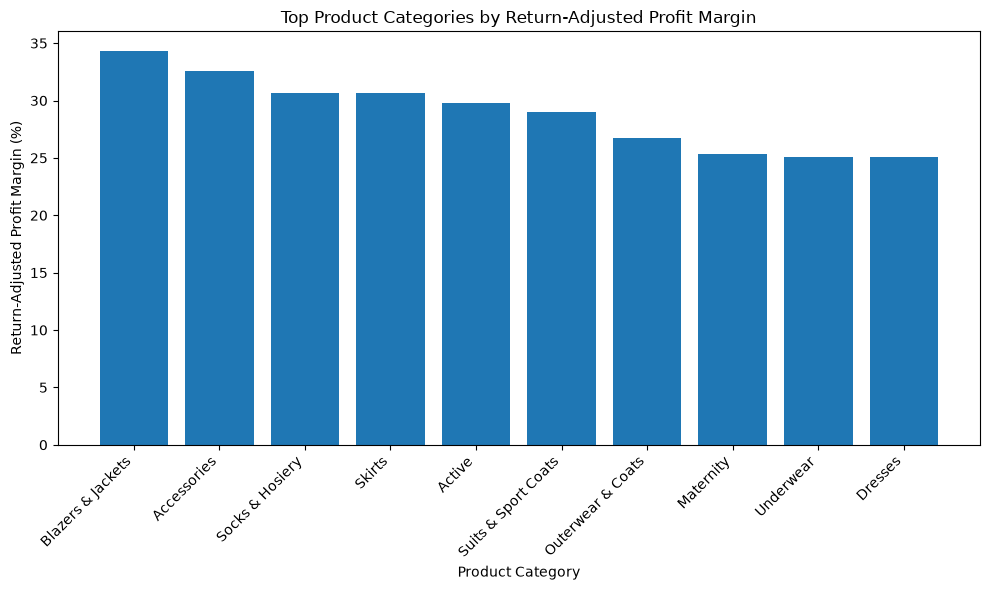

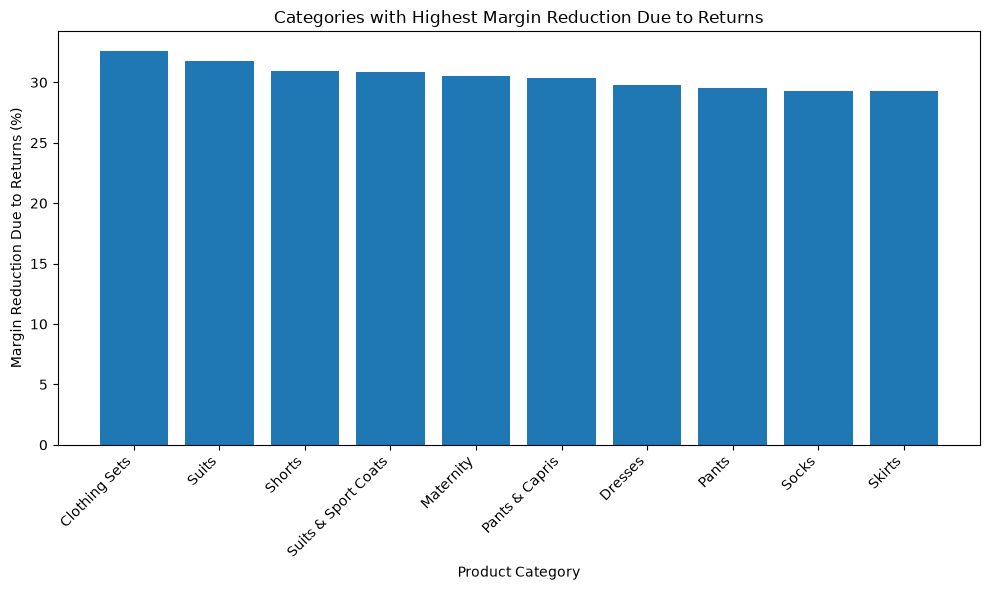

In [6]:
# Schritt 6: Diagramme für Research Question 2 erstellen
#
# Diagramm 1 zeigt die Kategorien mit der höchsten echten Profit Margin.
# Diagramm 2 zeigt die Kategorien, bei denen Retouren die Marge
# am stärksten reduzieren.

# ------------------------------------------------------------
# Diagramm 1: Top-Kategorien nach Return-Adjusted Profit Margin
# ------------------------------------------------------------

# Die zehn profitabelsten Kategorien auswählen.
top_categories = category_profit.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_categories["category"],
    top_categories["return_adjusted_profit_margin"] * 100
)

plt.xticks(rotation=45, ha="right")
plt.title("Top Product Categories by Return-Adjusted Profit Margin")
plt.xlabel("Product Category")
plt.ylabel("Return-Adjusted Profit Margin (%)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Diagramm 2: Größter Margenverlust durch Retouren
# ------------------------------------------------------------

# Die zehn Kategorien auswählen, bei denen Retouren
# die Profit Margin am stärksten reduzieren.
return_impact = category_profit.sort_values(
    "margin_reduction_due_to_returns",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    return_impact["category"],
    return_impact["margin_reduction_due_to_returns"] * 100
)

plt.xticks(rotation=45, ha="right")
plt.title("Categories with Highest Margin Reduction Due to Returns")
plt.xlabel("Product Category")
plt.ylabel("Margin Reduction Due to Returns (%)")
plt.tight_layout()
plt.show()